# EcoSort Waste Management Assistant
# Module 8 Summative Lab

This notebook builds an assistant that helps identify waste from images or short descriptions and then gives recycling guidance from policy documents. I approach it in stages because each part depends on the one before it: first I inspect and prepare the data, then build the image and text classifiers, then connect the policy retrieval and instruction generation, and a test for the complete assistant.


## Part 1: Dataset Exploration and Preparation

In [1]:
import os, re, json, random, pathlib, collections, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
%pip install h5py
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED); random.seed(SEED); tf.random.set_seed(SEED)
IMG_HEIGHT = IMG_WIDTH = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE
print("TF", tf.__version__)

Note: you may need to restart the kernel to use updated packages.
TF 2.21.0


### RealWaste images

I start with the image dataset for the CNN. Checking the class counts first will help me see whether the model will have roughly equal examples to learn from or whether some categories could dominate training. I should also inspect sample images and their dimensions to understand what the model is being asked to distinguish.


Textile Trash          318
Food Organics          411
Glass                  420
Vegetation             436
Cardboard              461
Miscellaneous Trash    495
Paper                  500
Metal                  790
Plastic                921
dtype: int64 
Total: 4752
Imbalance ratio (max/min): 2.90


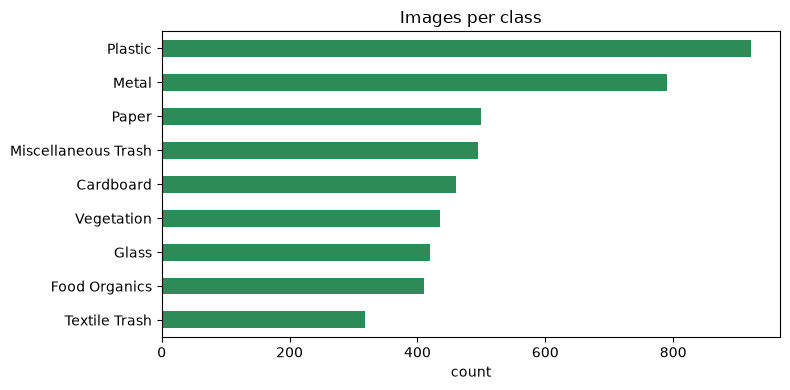

In [ ]:
data_dir = pathlib.Path("RealWaste") 
EXTS = {".jpg", ".jpeg", ".png"}
class_names = sorted(p.name for p in data_dir.iterdir() if p.is_dir())
num_classes = len(class_names)

paths, labels = [], []
for i, c in enumerate(class_names):
    for p in sorted((data_dir / c).iterdir()):
        if p.suffix.lower() in EXTS:
            paths.append(str(p)); labels.append(i)
labels = np.array(labels)

counts = pd.Series(collections.Counter(class_names[l] for l in labels)).sort_values()
print(counts, "\nTotal:", len(paths))
print("Imbalance ratio (max/min): %.2f" % (counts.max() / counts.min()))

fig, ax = plt.subplots(figsize=(8, 4))
counts.plot.barh(ax=ax, color="seagreen")
ax.set_title("Images per class"); ax.set_xlabel("count")
plt.tight_layout(); plt.show()

The dataset is not evenly balanced, so I need to track per-class results later instead of judging the CNN by accuracy alone.

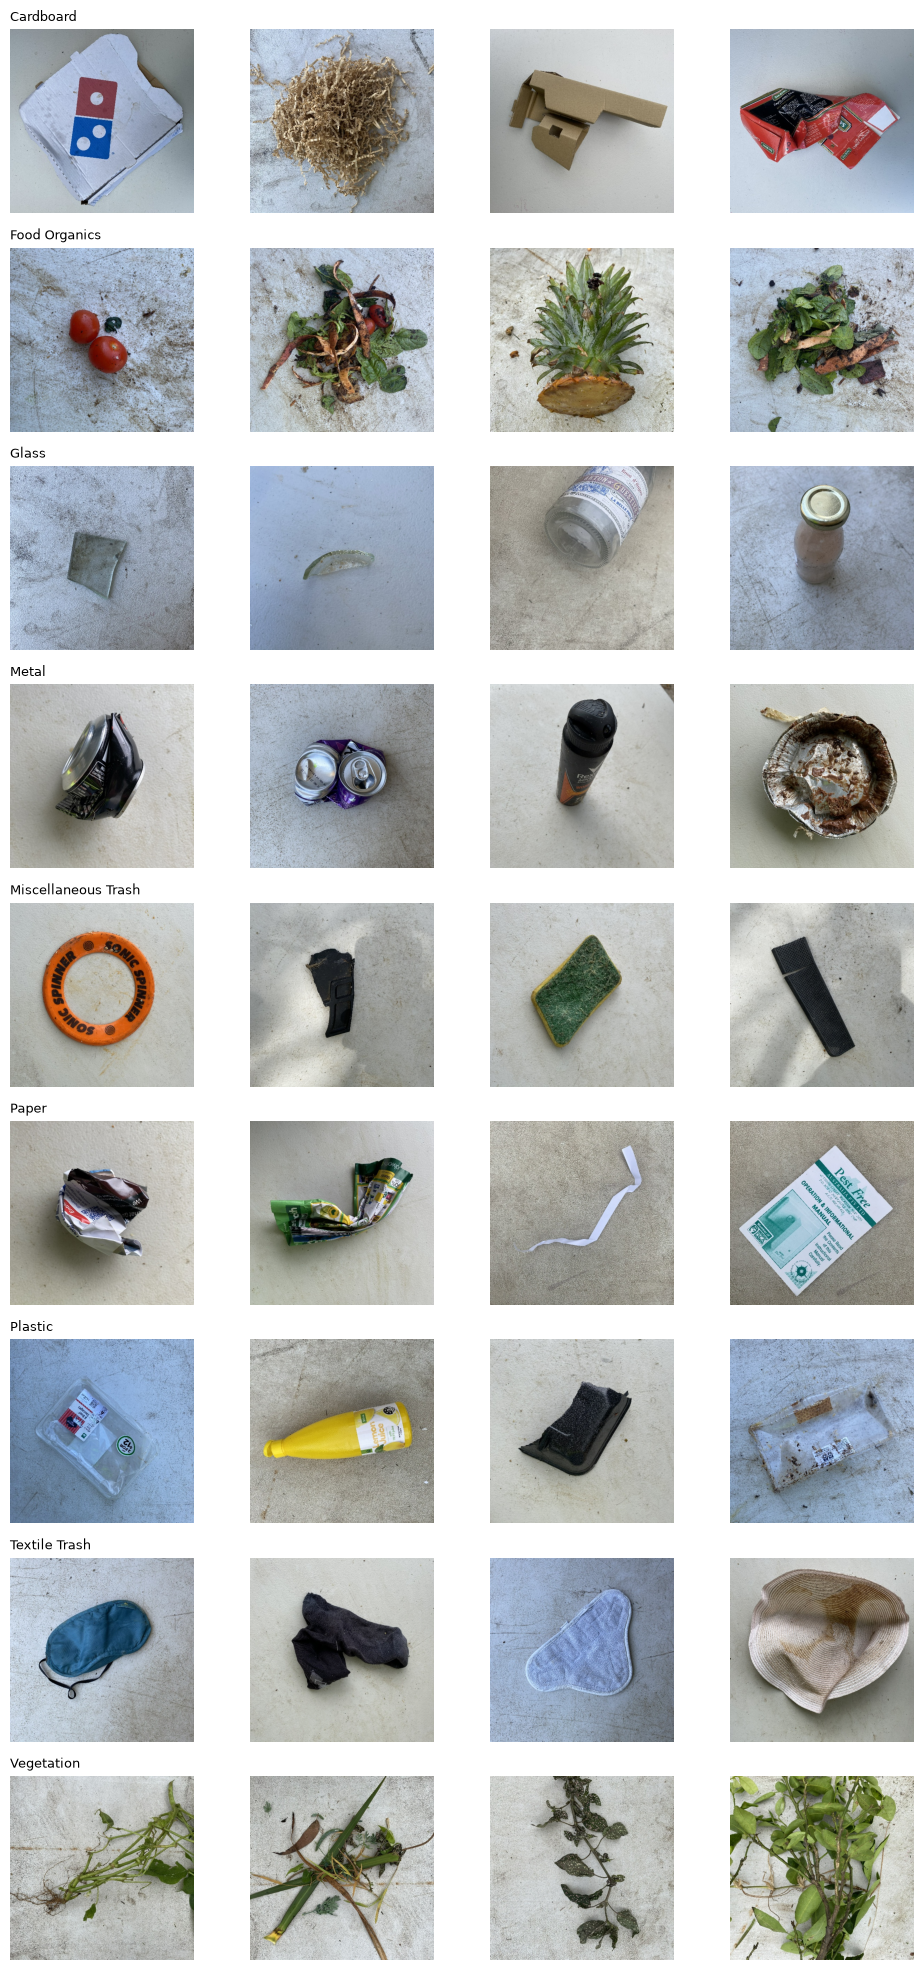

Image sizes seen in sample: {(524, 524): 36}


In [ ]:
# Sample images per class 
from PIL import Image
fig, axes = plt.subplots(num_classes, 4, figsize=(10, 2.2 * num_classes))
sizes = collections.Counter()
for i, c in enumerate(class_names):
    cls_paths = [p for p, l in zip(paths, labels) if l == i]
    for j, p in enumerate(random.sample(cls_paths, 4)):
        im = Image.open(p); sizes[im.size] += 1
        axes[i, j].imshow(im); axes[i, j].axis("off")
        if j == 0: axes[i, j].set_title(c, fontsize=9, loc="left")
plt.tight_layout(); plt.show()
print("Image sizes seen in sample:", dict(sizes))

The sampled images all have the same observed dimensions (524 × 524), which makes batching more straightforward. Still there are visual variation, like... the material, background, lighting, and camera angle can still differ.

 There are 4,752 images across nine classes. Plastic has the most examples (921), while Textile Trash has the fewest (318), giving an imbalance ratio of about 2.9 to 1. This matters because a model can become better at the common categories while struggling with the smaller ones. The sample images also show that this is a visual classification problem, so similar-looking materials and differences in lighting, backgrounds, or how an item is photographed can affect the predictions.


### Split strategy

I split the file paths into training, validation, and test sets before creating the image datasets. Doing it at the file-path level helps prevent the same image from leaking into more than one split. Using stratification so each split keeps a similar proportion of each category. 


In [4]:
from sklearn.model_selection import train_test_split
tr_p, tmp_p, tr_l, tmp_l = train_test_split(paths, labels, test_size=0.30, stratify=labels, random_state=SEED)
va_p, te_p, va_l, te_l   = train_test_split(tmp_p, tmp_l, test_size=0.50, stratify=tmp_l, random_state=SEED)
print(len(tr_p), len(va_p), len(te_p))
assert not (set(tr_p) & set(va_p)) and not (set(tr_p) & set(te_p)) and not (set(va_p) & set(te_p))

def load_img(path, label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_HEIGHT, IMG_WIDTH))
    img.set_shape((IMG_HEIGHT, IMG_WIDTH, 3))
    return img, tf.one_hot(label, num_classes)

def make_ds(p, l, training=False):
    ds = tf.data.Dataset.from_tensor_slices((p, l))
    if training: ds = ds.shuffle(len(p), seed=SEED, reshuffle_each_iteration=True)
    return ds.map(load_img, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_ds(tr_p, tr_l, True)
val_ds   = make_ds(va_p, va_l)
test_ds  = make_ds(te_p, te_l)       # not shuffled, so label order is known (te_l)

3326 713 713


The split is now fixed at 70% training, 15% validation, and 15% testing. I am keep these groups separate so later performance estimates are less likely have leakage.

The split produced 3,326 training images, 713 validation images, and 713 test images... Some categories still have fewer examples, so their individual scores can be less stable than the overall accuracy.


### Text descriptions

The image model is only one way a person might describe waste, so I also inspect the text dataset.

(5000, 5) ['description', 'category', 'disposal_instruction', 'common_confusion', 'material_composition']


,description,category,disposal_instruction,common_confusion,material_composition
0,soiled silver tablecloth,Textile Trash,Look for textile recycling programs in your area.,NaN,"Fabric made from natural or synthetic fibers, ..."
1,folded glass bottle leaking,Glass,"Remove caps, lids, and corks before recycling.",NaN,"Silica-based material, may contain additives f..."
2,large Supermarket vegetable waste with food re...,Food Organics,"If no compost available, place in general waste.",NaN,Biodegradable matter derived from plant or ani...
3,intact floral carpet piece,Textile Trash,Look for textile recycling programs in your area.,NaN,"Fabric made from natural or synthetic fibers, ..."
4,empty fun-sized purple apple core,Food Organics,Keep separate from recyclable materials.,Meat and dairy products may be restricted in s...,Biodegradable matter derived from plant or ani...


text: description | label: category


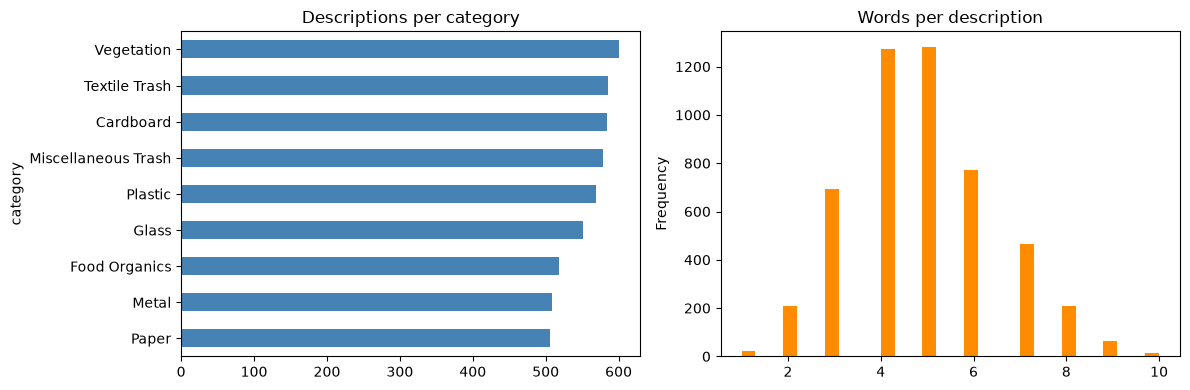

count    5000.000000
mean        4.854000
std         1.549956
min         1.000000
25%         4.000000
50%         5.000000
75%         6.000000
max        10.000000
Name: n_words, dtype: float64
Missing values:
 description    0
category       0
dtype: int64


In [5]:
df = pd.read_csv("waste_descriptions.csv")
print(df.shape, df.columns.tolist())
display(df.head())

text_col  = [c for c in df.columns if "desc" in c.lower() or "text" in c.lower()][0]
label_col = [c for c in df.columns if any(k in c.lower() for k in ("cat", "label", "class"))][0]
print("text:", text_col, "| label:", label_col)

df["n_words"] = df[text_col].astype(str).str.split().str.len()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df[label_col].value_counts().sort_values().plot.barh(ax=ax[0], color="steelblue"); ax[0].set_title("Descriptions per category")
df["n_words"].plot.hist(bins=30, ax=ax[1], color="darkorange"); ax[1].set_title("Words per description")
plt.tight_layout(); plt.show()
print(df["n_words"].describe())
print("Missing values:\n", df[[text_col, label_col]].isna().sum())

The initial inspection confirms that the text data has the fields needed for classification and later error analysis. I should check for duplicates next because repeated templates could make the model appear more general than it really is.

In [ ]:
# Duplicate(leakage check)
def normalize(t):
    t = str(t).lower()
    t = re.sub(r"[^a-z0-9\s\-']", " ", t)
    return re.sub(r"\s+", " ", t).strip()

df["norm"] = df[text_col].map(normalize)
n_dup = df.duplicated("norm").sum()
print(f"Exact duplicate descriptions after normalisation: {n_dup} of {len(df)}")
conflict = df.groupby("norm")[label_col].nunique()
print("Descriptions that appear under >1 category:", (conflict > 1).sum())

# most common opening phrases show how templated the data is
print(df["norm"].str.split().str[:3].str.join(" ").value_counts().head(10))

Exact duplicate descriptions after normalisation: 61 of 5000
Descriptions that appear under >1 category: 0
norm
broken brand b          4
torn large patterned    3
cd case                 3
torn brand a            3
envelope                3
glass vase              3
damaged medium red      3
clamshell packaging     3
water bottle            3
glass tabletop          3
Name: count, dtype: int64


The text file contains 5,000 rows and five columns, including a description and its category. After normalising the descriptions, I found 61 exact duplicates, and none of the normalised descriptions appeared under more than one category. I remove the duplicates before splitting the data so repeated examples do not make the evaluation look better than it should.

One limitation is that these descriptions are synthetic and often follow regular patterns. That makes them useful for testing the pipeline, but they may be much easier to classify than messy descriptions written by residents. The image data also comes from a particular facility, so its photos may not fully represent phone photos taken in different places.


In [ ]:
# Text split: de-duplicate FIRST, then stratified 80/20 
df_u = df.drop_duplicates("norm").reset_index(drop=True)
X = df_u[text_col].astype(str); y = df_u[label_col].astype(str)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("train", len(X_train), "test", len(X_test), "| removed duplicates:", len(df) - len(df_u))

train 3951 test 988 | removed duplicates: 61


### Policy documents

The final part of the assistant needs reliable recycling guidance. I load the policy documents and inspect their structure so I can retrieve relevant sections later. The assistant should use these documents as its source for instructions instead of inventing advice from the predicted label alone.


In [8]:
docs = json.load(open("waste_policy_documents.json"))
print(type(docs), len(docs))
sample = docs[0] if isinstance(docs, list) else list(docs.items())[0]
print(json.dumps(sample, indent=2)[:800])

<class 'list'> 14
{
  "policy_id": 1,
  "policy_type": "Textile Trash Recycling Guidelines",
  "categories_covered": [
    "Textile Trash"
  ],
  "effective_date": "2023-11-04",
  "document_text": "TEXTILE RECYCLING GUIDELINES\n\nAcceptable Items:\n- Clean clothing (all conditions)\n- Towels, sheets, and linens\n- Fabric scraps\n- Curtains and cloth napkins\n- Handbags and backpacks made of fabric\n- Soft toys and stuffed animals\n\nNon-Acceptable Items:\n- Wet or moldy textiles\n- Heavily soiled items\n- Carpets and rugs\n- Footwear\n- Items with significant non-textile parts\n\nCollection Method:\nPlace items in dedicated textile recycling bins or donate to local thrift stores.\n\nPreparation Instructions:\n- Ensure all items are clean and dry\n- Remove non-textile components when possible\n- Bag similar 


There are 14 policy documents. I keep their sections and category coverage because those details will help the retriever find the right guidance instead of treating all policy text as one undifferentiated block.

## Part 2: Waste Material Classification with CNN

Now that the image data is prepared, I build a CNN-based classifier. I use MobileNetV2 with ImageNet pretrained weights because training a deep image model from scratch can be difficult with a dataset of this size. Transfer learning gives the model useful visual features to start from, and then I can adapt those features to the waste categories. I also use class weights to reduce the effect of the class imbalance.


**Why MobileNetV2:** It is relatively lightweight, which makes it a reasonable starting point for an assistant that could eventually accept phone uploads. The model includes the required preprocessing and augmentation, helping keep the image preparation consistent between training and prediction.

In [9]:
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from sklearn.utils.class_weight import compute_class_weight

cw = compute_class_weight("balanced", classes=np.arange(num_classes), y=tr_l)
class_weights = dict(enumerate(cw))
print({class_names[k]: round(v, 2) for k, v in class_weights.items()})

augment = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
], name="augmentation")

def build_model(lr=1e-3, dropout=0.3, dense_units=128):
    base = MobileNetV2(input_shape=(IMG_HEIGHT, IMG_WIDTH, 3), include_top=False, weights="imagenet")
    base.trainable = False
    inp = layers.Input((IMG_HEIGHT, IMG_WIDTH, 3))
    x = augment(inp)
    x = layers.Lambda(preprocess_input, name="mobilenet_preprocess")(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(dense_units, activation="relu", kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = layers.Dropout(dropout / 2)(x)
    out = layers.Dense(num_classes, activation="softmax")(x)
    m = models.Model(inp, out)
    m.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="categorical_crossentropy", metrics=["accuracy"])
    return m, base

model, base = build_model()
model.summary()

{'Cardboard': np.float64(1.14), 'Food Organics': np.float64(1.28), 'Glass': np.float64(1.26), 'Metal': np.float64(0.67), 'Miscellaneous Trash': np.float64(1.07), 'Paper': np.float64(1.06), 'Plastic': np.float64(0.57), 'Textile Trash': np.float64(1.66), 'Vegetation': np.float64(1.21)}



Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_preprocess (Lambda)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,113 (9.24 MB)

 Trainable params: 165,129 (645.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### Hyperparameter search

Before committing to one configuration, I compare a small set of learning rates, dropout values, and dense-layer sizes while keeping the pretrained base frozen. This gives me a practical way to choose a starting configuration without running a large search. I use validation accuracy for the comparison rather than the test set, so the final test evaluation remains separate.


In [10]:
configs = [dict(lr=1e-3, dropout=0.3, dense_units=128),
           dict(lr=3e-4, dropout=0.3, dense_units=128),
           dict(lr=1e-3, dropout=0.5, dense_units=256)]
results = []
for cfg in configs:
    m, _ = build_model(**cfg)
    h = m.fit(train_ds, validation_data=val_ds, epochs=4, class_weight=class_weights, verbose=0)
    results.append({**cfg, "best_val_acc": max(h.history["val_accuracy"]), "final_train_acc": h.history["accuracy"][-1]})
    print(results[-1])
search_df = pd.DataFrame(results).sort_values("best_val_acc", ascending=False)
display(search_df)
best_cfg = {k: search_df.iloc[0][k] for k in ("lr", "dropout", "dense_units")}
best_cfg["dense_units"] = int(best_cfg["dense_units"]); print("Best:", best_cfg)

{'lr': 0.001, 'dropout': 0.3, 'dense_units': 128, 'best_val_acc': 0.7812061905860901, 'final_train_acc': 0.7411304712295532}
{'lr': 0.0003, 'dropout': 0.3, 'dense_units': 128, 'best_val_acc': 0.7194951176643372, 'final_train_acc': 0.6849067807197571}
{'lr': 0.001, 'dropout': 0.5, 'dense_units': 256, 'best_val_acc': 0.7517531514167786, 'final_train_acc': 0.6942272782325745}


,lr,dropout,dense_units,best_val_acc,final_train_acc
0,0.0010,0.3,128,0.781206,0.741130
2,0.0010,0.5,256,0.751753,0.694227
1,0.0003,0.3,128,0.719495,0.684907


Best: {'lr': np.float64(0.001), 'dropout': np.float64(0.3), 'dense_units': 128}


The best validation result came from learning rate 0.001, dropout 0.3, and 128 dense units, with validation accuracy around 0.781. The other tested configurations scored lower, so I use this one for the next training stage.

### Training the classifier and fine-tunning

After choosing the best configuration, I train the classification head first. Then I fine-tune part of the pretrained network so the visual features can adapt to waste images. Early stopping helps avoid continuing training once validation performance stops improving, and restoring the best weights keeps the strongest validation version of the model.


In [11]:
model, base = build_model(**best_cfg)
es = callbacks.EarlyStopping(monitor="val_accuracy", patience=3, restore_best_weights=True)
hist_head = model.fit(train_ds, validation_data=val_ds, epochs=12, class_weight=class_weights, callbacks=[es])

# Stage 2: unfreeze the top of the base; keep BatchNorm frozen; much lower LR
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
model.compile(optimizer=tf.keras.optimizers.Adam(1e-5), loss="categorical_crossentropy", metrics=["accuracy"])
es2 = callbacks.EarlyStopping(monitor="val_accuracy", patience=3, restore_best_weights=True)
hist_ft = model.fit(train_ds, validation_data=val_ds, epochs=10, class_weight=class_weights, callbacks=[es2])
model.save("waste_cnn.keras")

Epoch 1/12
104/104 ━━━━━━━━━━━━━━━━━━━━ 975s 9s/step - accuracy: 0.5238 - loss: 1.3172 - val_accuracy: 0.6676 - val_loss: 0.9356
Epoch 2/12
104/104 ━━━━━━━━━━━━━━━━━━━━ 179s 2s/step - accuracy: 0.6852 - loss: 0.8525 - val_accuracy: 0.7167 - val_loss: 0.8207
Epoch 3/12
104/104 ━━━━━━━━━━━━━━━━━━━━ 142s 1s/step - accuracy: 0.7126 - loss: 0.7662 - val_accuracy: 0.7461 - val_loss: 0.7251
Epoch 4/12
104/104 ━━━━━━━━━━━━━━━━━━━━ 150s 1s/step - accuracy: 0.7444 - loss: 0.6959 - val_accuracy: 0.7546 - val_loss: 0.6962
Epoch 5/12
104/104 ━━━━━━━━━━━━━━━━━━━━ 175s 2s/step - accuracy: 0.7649 - loss: 0.6336 - val_accuracy: 0.7475 - val_loss: 0.7106
Epoch 6/12
104/104 ━━━━━━━━━━━━━━━━━━━━ 175s 1s/step - accuracy: 0.7595 - loss: 0.6508 - val_accuracy: 0.7475 - val_loss: 0.7170
Epoch 7/12
104/104 ━━━━━━━━━━━━━━━━━━━━ 152s 1s/step - accuracy: 0.7802 - loss: 0.5917 - val_accuracy: 0.7770 - val_loss: 0.6379
Epoch 8/12
104/104 ━━━━━━━━━━━━━━━━━━━━ 149s 1s/step - accuracy: 0.7974 - loss: 0.5440 - val_accu

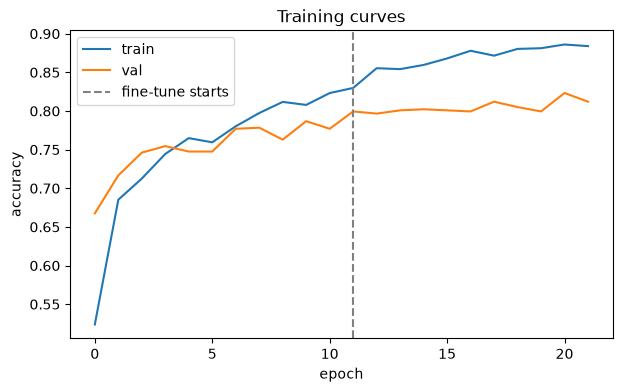

In [12]:
def plot_hist(*hs):
    acc = sum([h.history["accuracy"] for h in hs], []); val = sum([h.history["val_accuracy"] for h in hs], [])
    plt.figure(figsize=(7, 4)); plt.plot(acc, label="train"); plt.plot(val, label="val")
    plt.axvline(len(hs[0].history["accuracy"]) - 1, ls="--", c="gray", label="fine-tune starts")
    plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.legend(); plt.title("Training curves"); plt.show()
plot_hist(hist_head, hist_ft)

### Evaluating test set

The test set is the final check because these images were not used to choose the configuration or train the model. I look at accuracy alongside the classification report and confusion matrix. 


Test accuracy: 0.825
                     precision    recall  f1-score   support

          Cardboard      0.884     0.884     0.884        69
      Food Organics      0.911     0.823     0.864        62
              Glass      0.725     0.794     0.758        63
              Metal      0.861     0.788     0.823       118
Miscellaneous Trash      0.750     0.680     0.713        75
              Paper      0.873     0.920     0.896        75
            Plastic      0.738     0.775     0.756       138
      Textile Trash      0.827     0.896     0.860        48
         Vegetation      0.940     0.969     0.955        65

           accuracy                          0.825       713
          macro avg      0.834     0.837     0.834       713
       weighted avg      0.826     0.825     0.824       713



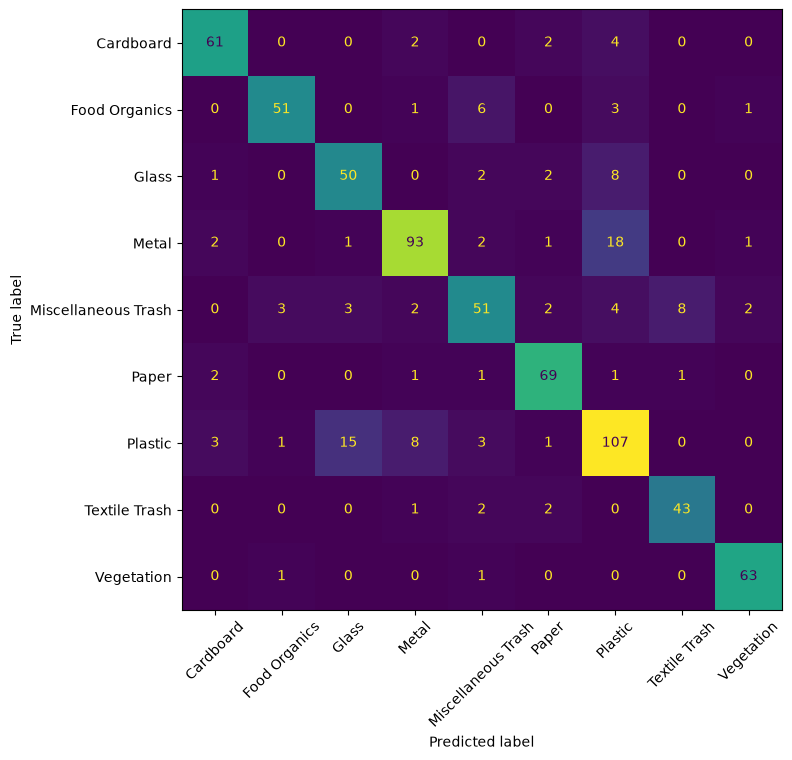

Most common confusions (true -> predicted):
  Metal -> Plastic: 18
  Plastic -> Glass: 15
  Glass -> Plastic: 8
  Plastic -> Metal: 8
  Miscellaneous Trash -> Textile Trash: 8


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
probs = model.predict(test_ds, verbose=0)
y_true = np.array(te_l); y_pred = probs.argmax(1)
print("Test accuracy: %.3f" % (y_true == y_pred).mean())
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=class_names).plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.tight_layout(); plt.show()

cm = confusion_matrix(y_true, y_pred); np.fill_diagonal(cm, 0)
top = np.dstack(np.unravel_index(np.argsort(-cm.ravel())[:5], cm.shape))[0]
print("Most common confusions (true - predicted):")
for t, p in top: print(f"  {class_names[t]} - {class_names[p]}: {cm[t, p]}")

The confusion matrix shows where its remaining errors cluster. In particular, Metal, Plastic, and Glass are sometimes visually confused, so the assistant should not present every image prediction as guaranteed.

Miscellaneous Trash    0.713287
Plastic                0.756184
Glass                  0.757576
dtype: float64 <- hardest classes


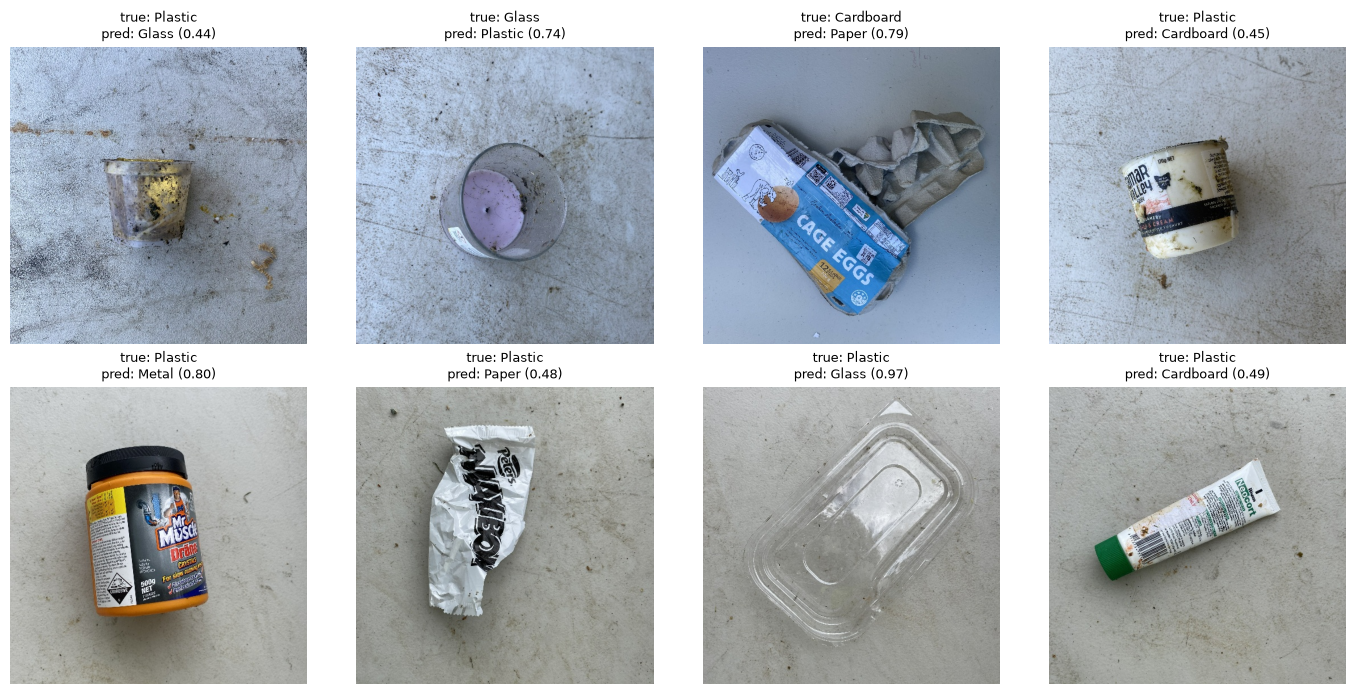

In [14]:
# Hardest classes + misclassified examples
f1 = pd.Series(classification_report(y_true, y_pred, target_names=class_names, output_dict=True)).drop(["accuracy", "macro avg", "weighted avg"])
print(pd.Series({k: v["f1-score"] for k, v in f1.items()}).sort_values().head(3), "<- hardest classes")

wrong = np.where(y_true != y_pred)[0]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, i in zip(axes.ravel(), np.random.choice(wrong, min(8, len(wrong)), replace=False)):
    ax.imshow(Image.open(te_p[i])); ax.axis("off")
    ax.set_title(f"true: {class_names[y_true[i]]}\npred: {class_names[y_pred[i]]} ({probs[i].max():.2f})", fontsize=9)
plt.tight_layout(); plt.show()

The CNN reached **82.5% test accuracy**. The hardest classes by F1 were Miscellaneous Trash (0.713), Plastic (0.756), and Glass (0.758). The most common confusions included Metal being predicted as Plastic 18 times and Plastic being predicted as Glass 15 times. Those mistakes make sense for materials that can share visual features, but they also show that the model is not reliable enough to treat every prediction as certain. The class weights and transfer learning helped, although the results show that performance is not equal across all categories.


## Part 3: Waste Description Classification

Next I build a classifier for people who describe an item in words rather than upload a photo. TF-IDF turns the text into numerical features based on word and character patterns. Character n-grams are useful here because they can still capture part of a word when someone makes a spelling mistake. I compare several models with cross-validation on the training data, then evaluate the selected model on the held-out test set.


I use a classical text model because the dataset is small and short descriptions often work well with TF-IDF features. Comparing Logistic Regression, LinearSVC, Naive Bayes, and Random Forest lets me choose based on evidence instead of assuming one model will be best. I also tune the selected model's regularisation strength using cross-validation.


In [15]:
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import cross_val_score, StratifiedKFold

def make_features():
    return FeatureUnion([
        ("word", TfidfVectorizer(preprocessor=normalize, ngram_range=(1, 2), sublinear_tf=True, min_df=1)),
        ("char", TfidfVectorizer(preprocessor=normalize, analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True, min_df=2)),
    ])

candidates = {
    "LogReg":       LogisticRegression(max_iter=2000, C=5),
    "LinearSVC":    CalibratedClassifierCV(LinearSVC(C=1), cv=3),
    "NaiveBayes":   MultinomialNB(alpha=0.1),
    "RandomForest": RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
}
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
cv_scores = {}
for name, clf_ in candidates.items():
    pipe = Pipeline([("feat", make_features()), ("clf", clf_)])
    s = cross_val_score(pipe, X_train, y_train, cv=skf, scoring="f1_macro", n_jobs=-1)
    cv_scores[name] = (s.mean(), s.std()); print(f"{name:13s} macro-F1 {s.mean():.4f} +/- {s.std():.4f}")
best_name = max(cv_scores, key=lambda k: cv_scores[k][0]); print("Selected:", best_name)

LogReg        macro-F1 0.9965 +/- 0.0025
LinearSVC     macro-F1 0.9992 +/- 0.0010
NaiveBayes    macro-F1 0.9910 +/- 0.0046
RandomForest  macro-F1 0.9679 +/- 0.0058
Selected: LinearSVC


LinearSVC had the strongest cross-validation macro-F1 among the tested models, so I carry it forward.

In [ ]:
# tuning the selected model 
from sklearn.model_selection import GridSearchCV
pipe = Pipeline([("feat", make_features()), ("clf", candidates[best_name])])
param_name = {"LogReg": "clf__C", "LinearSVC": "clf__estimator__C", "NaiveBayes": "clf__alpha", "RandomForest": "clf__n_estimators"}[best_name]
grid = {"LogReg": [0.5, 2, 5, 20], "LinearSVC": [0.1, 1, 5], "NaiveBayes": [0.01, 0.1, 1], "RandomForest": [200, 400]}[best_name]
gs = GridSearchCV(pipe, {param_name: grid}, cv=skf, scoring="f1_macro", n_jobs=-1).fit(X_train, y_train)
print(gs.best_params_, round(gs.best_score_, 4))
text_model = gs.best_estimator_

{'clf__estimator__C': 5} 0.9995


The tuning step selected `C = 5` gave the strongest cross-validation score among the tested regularisation values.

### Evaluate on the held-out test set

After selecting and tuning the model, I test it on descriptions kept aside from training. I review the classification report and confusion matrix, then inspect low-confidence examples and manually written hard cases, a test set made from synthetic descriptions may not reflect on the variety of real user input.


Test accuracy: 1.0000
                     precision    recall  f1-score   support

          Cardboard      1.000     1.000     1.000       116
      Food Organics      1.000     1.000     1.000       102
              Glass      1.000     1.000     1.000       108
              Metal      1.000     1.000     1.000       101
Miscellaneous Trash      1.000     1.000     1.000       116
              Paper      1.000     1.000     1.000        99
            Plastic      1.000     1.000     1.000       111
      Textile Trash      1.000     1.000     1.000       117
         Vegetation      1.000     1.000     1.000       118

           accuracy                          1.000       988
          macro avg      1.000     1.000     1.000       988
       weighted avg      1.000     1.000     1.000       988



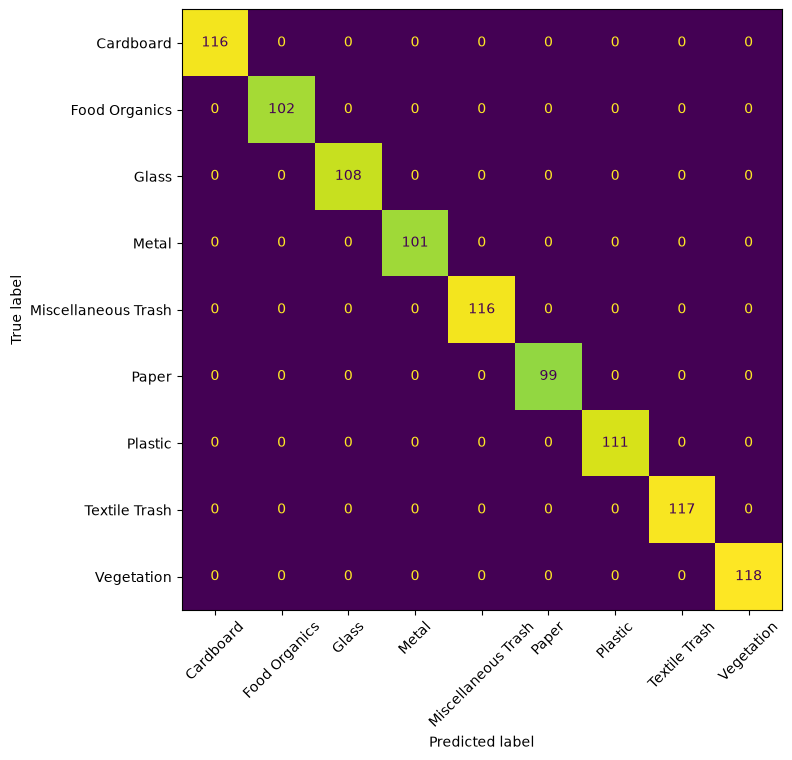

In [17]:
pred = text_model.predict(X_test)
print("Test accuracy: %.4f" % (pred == y_test).mean())
print(classification_report(y_test, pred, digits=3))
labels_t = sorted(y.unique())
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=labels_t), display_labels=labels_t).plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.tight_layout(); plt.show()

In [ ]:
# misclassified test descriptions and low-confidence ones
proba = text_model.predict_proba(X_test)
err = pd.DataFrame({"text": X_test.values, "true": y_test.values, "pred": pred, "conf": proba.max(1)})
print("Misclassified:", (err.true != err.pred).sum()); display(err[err.true != err.pred])
print("\nLowest-confidence (even if correct):"); display(err.sort_values("conf").head(8))

Misclassified: 0


,text,true,pred,conf



Lowest-confidence (even if correct):


,text,true,pred,conf
13,red glass pen,Miscellaneous Trash,Miscellaneous Trash,0.535101
152,standard plastic Commercial battery,Miscellaneous Trash,Miscellaneous Trash,0.595689
145,large paper bed sheet,Textile Trash,Textile Trash,0.601218
908,partial purple paper marker,Miscellaneous Trash,Miscellaneous Trash,0.604044
298,mini glass Eco-Friendly battery,Miscellaneous Trash,Miscellaneous Trash,0.640528
792,full black plastic Generic pen with contents,Miscellaneous Trash,Miscellaneous Trash,0.666146
15,damaged striped metal Local marker,Miscellaneous Trash,Miscellaneous Trash,0.669914
268,dirty small plastic Budget tool,Miscellaneous Trash,Miscellaneous Trash,0.681369


There are no errors in this held-out test split, but some correct predictions still have lower confidence. Looking at those cases helps reveal where the model may be less certain even when the label happens to be right.

In [ ]:
# Hand-written hard cases that synthetic data may not cover
hard = ["plastic bottel with the label still on", "greasy pizza box", "old t-shirt with a hole in it",
        "broken glass jar lid made of metal", "batteries from a remote control", "banana peel and coffee grounds",
        "thing", "a bag of stuff from the garage", "cardboard box wrapped in plastic film", "tetra pak juice carton"]
for t in hard:
    p = text_model.predict_proba([t])[0]; i = p.argmax()
    print(f"{t!r:50s} -> {text_model.classes_[i]:22s} ({p[i]:.2f})")

'plastic bottel with the label still on'           -> Plastic                (0.99)
'greasy pizza box'                                 -> Cardboard              (1.00)
'old t-shirt with a hole in it'                    -> Textile Trash          (1.00)
'broken glass jar lid made of metal'               -> Metal                  (0.50)
'batteries from a remote control'                  -> Miscellaneous Trash    (0.97)
'banana peel and coffee grounds'                   -> Food Organics          (1.00)
'thing'                                            -> Cardboard              (0.51)
'a bag of stuff from the garage'                   -> Paper                  (0.96)
'cardboard box wrapped in plastic film'            -> Cardboard              (0.85)
'tetra pak juice carton'                           -> Cardboard              (0.99)


The hand-written examples test inputs that may be less regular than the synthetic training data. They are not a replacement for a real-world evaluation, but they can expose obvious weaknesses before integration.

LinearSVC performed best in cross-validation, with a macro-F1 score of **0.9992 ± 0.0010**. Tuning selected `C = 5`, with a cross-validation score of 0.9995, and the held-out test accuracy was 100%. There were no misclassified examples in that test split. These results are extremely strong, but I should not assume the classifier will be perfect in real use: the descriptions are synthetic and highly templated, so the test set may be much easier than resident-written text.

The hand-written hard cases provide a more useful stress test. Most examples received plausible labels, but the broken glass jar lid received only 0.50 confidence. That is a reminder to check uncertainty and unusual wording, not just the headline accuracy.


In [20]:
def classify_waste_description(description, return_conf=False):
    p = text_model.predict_proba([str(description)])[0]; i = p.argmax()
    return (text_model.classes_[i], float(p[i])) if return_conf else text_model.classes_[i]
print(classify_waste_description("empty plastic water bottle", True))

('Plastic', 0.9992161716270545)


## Part 4: Recycling Instruction Generation with RAG

A category prediction alone does not tell someone how to recycle an item. For that, I use retrieval-augmented generation (RAG): the system searches the policy documents for relevant sections, then uses those sections to form instructions. I split the documents into smaller chunks so retrieval can return focused information instead of passing whole documents to the model.


The pipeline is: policy documents → section-based chunks → TF-IDF retrieval → a language model that answers from the retrieved text → a faithfulness check. Category metadata helps limit retrieval to policies relevant to the predicted waste type. If the generated answer does not pass the check, the system falls back to text taken directly from the retrieved policy sections. The fallback is less conversational, but it is safer than returning unsupported instructions.


In [21]:
def split_sections(text, max_words=120):
    out = []
    for sec in (s.strip() for s in re.split(r"\n\s*\n", text) if s.strip()):
        if len(sec.split()) < 6:            # drops the all-caps title line
            continue
        lines = sec.split("\n"); head, body = lines[0], lines[1:]
        if len(sec.split()) <= max_words or not body:
            out.append(sec)
        else:                               # very long section: split by lines, repeat the heading
            cur = []
            for ln in body:
                if cur and sum(len(x.split()) for x in cur) + len(ln.split()) > max_words:
                    out.append("\n".join([head] + cur)); cur = []
                cur.append(ln)
            if cur: out.append("\n".join([head] + cur))
    return out

rag_chunks = []
for d in docs:
    cats, ptype = d.get("categories_covered", []), d.get("policy_type", "")
    for sec in split_sections(d.get("document_text", "")):
        rag_chunks.append({"policy_id": d.get("policy_id"), "policy_type": ptype, "categories": cats,
                           "section": sec.split("\n")[0].rstrip(":"), "body": sec, "text": f"{ptype}. {sec}"})
print(len(docs), "documents ->", len(rag_chunks), "chunks")
print(collections.Counter(c["section"] for c in rag_chunks).most_common(8))
print("\nExample chunk:\n", rag_chunks[1]["text"])

14 documents -> 67 chunks
[('Benefits', 9), ('Acceptable Items', 8), ('Non-Acceptable Items', 8), ('Collection Method', 8), ('Preparation Instructions', 8), ('GENERAL REQUIREMENTS', 5), ('MISCELLANEOUS TRASH GUIDELINES', 3), ('VEGETATION GUIDELINES', 3)]

Example chunk:
 Textile Trash Recycling Guidelines. Non-Acceptable Items:
- Wet or moldy textiles
- Heavily soiled items
- Carpets and rugs
- Footwear
- Items with significant non-textile parts


The section-based chunking creates 67 chunks from the 14 documents. Smaller chunks give the retriever more specific passages to rank, while preserving the section name gives the generated answer useful context.

### Retrieval and tuning

I compare unigram and unigram-plus-bigram retrieval using hit@k to check whether a relevant policy section appears among the top retrieved results. The measure helps me choose a retrieval setup, although it is only an approximation of the full assistant because the query descriptions do not always name the category explicitly.


In [ ]:
def build_index(ngram=(1, 2)):
    v = TfidfVectorizer(ngram_range=ngram, stop_words="english", sublinear_tf=True)
    return v, v.fit_transform([c["text"] for c in rag_chunks])

rag_vec, rag_matrix = build_index((1, 2))

def retrieve_docs(query, k=4, category=None, vec=None, mat=None):
    vec = vec if vec is not None else rag_vec
    mat = mat if mat is not None else rag_matrix
    sims = (mat @ vec.transform([query]).T).toarray().ravel()
    if category:                                            
        mask = np.array([category in c["categories"] for c in rag_chunks])
        if mask.any(): sims = np.where(mask, sims, -1)
    idx = np.argsort(-sims)[:k]
    return [{**rag_chunks[i], "score": float(sims[i])} for i in idx if sims[i] > 0]

# Non-trivial retrieval test
# top-k chunks comes from a policy that covers the item's true category.
eval_q = df_u.sample(300, random_state=SEED)
rows = []
for ngram in [(1, 1), (1, 2)]:
    v, m = build_index(ngram)
    for k in [1, 3, 5]:
        hits = [any(row[label_col] in r["categories"] for r in retrieve_docs(f"how to dispose of {row[text_col]}", k, None, v, m))
                for _, row in eval_q.iterrows()]
        rows.append({"ngram": ngram, "k": k, "hit@k": round(float(np.mean(hits)), 3)})
display(pd.DataFrame(rows))

,ngram,k,hit@k
0,"(1, 1)",1,0.520
1,"(1, 1)",3,0.597
2,"(1, 1)",5,0.627
3,"(1, 2)",1,0.533
4,"(1, 2)",3,0.600
5,"(1, 2)",5,0.633


The bigram setup slightly improves retrieval hit@k in these checks: hit@5 rises from 0.627 with unigrams to 0.633 with unigrams and bigrams. The improvement is modest, but it supports using both single words and short phrases for matching policy text.

In [23]:
K = 4
for r in retrieve_docs("how to prepare and place Cardboard for recycling", K, category="Cardboard"):
    print(round(r["score"], 3), "|", r["section"], "|", r["body"][:110].replace("\n", " "))

0.532 | Collection Method | Collection Method: Flatten and place in recycling bins or take to cardboard recycling centers.
0.319 | Acceptable Items | Acceptable Items: - Corrugated cardboard boxes - Paperboard (cereal boxes, etc.) - Cardboard packaging - Cardb
0.311 | Benefits | Benefits: Recycling cardboard saves trees and reduces landfill volume significantly.
0.299 | Non-Acceptable Items | Non-Acceptable Items: - Waxed cardboard - Cardboard with food residue - Cardboard with plastic linings - Foam 


For this Cardboard query, the top result is the Collection Method section, followed by Acceptable Items and Benefits. That is relevant context for a recycling question, although the retrieved sections still need to be checked for completeness and accuracy.

### Generate instructions with a language model

Once retrieval finds policy sections, I pass that context to FLAN-T5 to produce readable instructions. The important constraint is that the model should use the retrieved policy rather than add its own unsupported details. Since language models can still generate content that is not grounded in the source, the next step checks the answer and uses an extractive fallback when needed.


In [ ]:
# loading the model
try:
    import torch
    from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
    LM_NAME = "google/flan-t5-base"           
    tok = AutoTokenizer.from_pretrained(LM_NAME)
    lm = AutoModelForSeq2SeqLM.from_pretrained(LM_NAME).eval()
    def lm_generate(prompt, max_new_tokens=200):
        enc = tok(prompt, return_tensors="pt", truncation=True, max_length=512)
        with torch.no_grad():
            out = lm.generate(**enc, max_new_tokens=max_new_tokens, num_beams=4, no_repeat_ngram_size=3)
        return tok.decode(out[0], skip_special_tokens=True)
    print("LM loaded:", LM_NAME)
except Exception as e:
    lm_generate = None; print("LM unavailable, extractive fallback only:", repr(e))

STOP = set("the a an and or of to in on for with is are be it this that you your if as at by from not do does can will should must may".split())
def content_words(t): return {w for w in re.findall(r"[a-z]{4,}", t.lower()) if w not in STOP}

def faithfulness(generated, context):
    gw = content_words(generated)
    return len(gw & content_words(context)) / len(gw) if gw else 0.0

def syllables(w):
    w = w.lower(); n = len(re.findall(r"[aeiouy]+", w)); n -= (w.endswith("e") and n > 1)
    return max(1, n)
def flesch(text):
    sents = max(1, len([s for s in re.split(r"[.!?\n]+", text) if s.strip()]))   # a line break counts as a sentence end
    words = re.findall(r"[A-Za-z']+", text) or ["x"]
    return 206.835 - 1.015 * len(words) / sents - 84.6 * sum(map(syllables, words)) / len(words)

Loading weights: 100%|██████████| 282/282 [00:04<00:00, 61.65it/s] 
[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


LM loaded: google/flan-t5-base


In [25]:
FAITH_MIN = 0.6
def extractive_instructions(category, retrieved):
    return f"{category}: guidance from {retrieved[0]['policy_type']}\n\n" + "\n\n".join(r["body"] for r in retrieved)

def generate_instructions(category, query=None):
    q = query or f"how to prepare, collect and place {category} for recycling; items not accepted"
    retrieved = retrieve_docs(q, K, category=category)
    if not retrieved:
        return {"instructions": f"No city policy was found for '{category}'. Please contact Metro City waste services.",
                "retrieved": [], "faithfulness": None, "mode": "no_policy"}
    context = "\n".join(r["body"] for r in retrieved)
    context = " ".join(context.split()[:280])               # keep the prompt inside the T5 input limit
    if lm_generate is not None:
        prompt = (f"Write a short numbered list of steps telling a resident how to recycle {category}. "
                  f"Use only the information below.\n\n{context}\n\nSteps:")
        out = lm_generate(prompt)
        f = faithfulness(out, context)
        if f >= FAITH_MIN and len(out.split()) > 8:
            return {"instructions": out, "retrieved": retrieved, "faithfulness": round(f, 2), "mode": "generated"}
        return {"instructions": extractive_instructions(category, retrieved), "retrieved": retrieved,
                "faithfulness": round(f, 2), "mode": "fallback"}
    return {"instructions": extractive_instructions(category, retrieved), "retrieved": retrieved, "faithfulness": None, "mode": "extractive"}

def generate_recycling_instructions(waste_category):
    return generate_instructions(waste_category)

### Evaluate the generated instructions

I evaluate the instruction pipeline across all nine waste categories. I track whether each answer was generated or fell back to extracted policy text, along with a word-overlap faithfulness score, readability, and answer length. These measurements give a basic picture of the output, but they cannot replace checking the instructions against the source policy.


In [ ]:
rows, examples = [], {}
for c in class_names:
    r = generate_instructions(c); examples.setdefault(r["mode"], (c, r["instructions"]))
    rows.append({"category": c, "mode": r["mode"], "faithfulness": r["faithfulness"],
                 "flesch_reading_ease": round(flesch(r["instructions"]), 1), "n_words": len(r["instructions"].split())})
eval_df = pd.DataFrame(rows); display(eval_df)
print(eval_df["mode"].value_counts().to_dict())
print(eval_df[["faithfulness", "flesch_reading_ease", "n_words"]].astype(float).describe().loc[["mean", "min", "max"]])
for mode, (c, text) in examples.items():
    print(f"\n EXAMPLE ({mode}): {c} \n{text}")

,category,mode,faithfulness,flesch_reading_ease,n_words
0,Cardboard,generated,1.00,35.9,45
1,Food Organics,fallback,0.33,41.4,69
2,Glass,generated,0.93,50.3,17
3,Metal,generated,0.88,57.2,35
4,Miscellaneous Trash,generated,1.00,16.1,20
5,Paper,generated,1.00,31.6,48
6,Plastic,generated,0.71,36.1,40
7,Textile Trash,fallback,1.00,37.6,76
8,Vegetation,fallback,0.50,43.1,74


{'generated': 6, 'fallback': 3}
      faithfulness  flesch_reading_ease    n_words
mean      0.816667            38.811111  47.111111
min       0.330000            16.100000  17.000000
max       1.000000            57.200000  76.000000

===== example (generated): Cardboard =====
Place cardboard in recycling bins or take to cardboard recycling centers. Acceptable Items: - Corrugated cardboard boxes - Paperboard (cereal boxes, etc.) - Cardboard tubes - Clean pizza boxes Non-Acceptable Items - Waxed cardboard - cardboard with food residue - Foam inserts - Packing peanuts

===== example (fallback): Food Organics =====
Food Organics: guidance from Food Organics Recycling Guidelines

Collection Method:
Use dedicated food waste bins lined with compostable bags.

Benefits:
Food waste recycling reduces methane emissions and creates valuable compost.

Preparation Instructions:
- Remove all packaging
- Drain excess liquids
- Use compostable bags if required

Non-Acceptable Items:
- Packaging of a

The evaluation shows that the faithfulness guardrail sends some categories to fallback rather than allowing a weak generated answer through. This trades a more natural response for a more cautious one when the source support is insufficient.

The evaluation returned generated answers for **6 categories** and used the fallback for **3**. The mean faithfulness score was about **0.817**, and the average Flesch reading-ease score was about **38.8**, so the outputs are not consistently easy to read. The fallback is triggered when the faithfulness check does not meet the threshold, which is a useful safety measure even though the result may be less natural.

Word-overlap faithfulness is only a rough check: it can catch some unsupported wording but may miss a subtle error, such as a wrong number or a small change in meaning. I would still review several outputs against their retrieved policy sections before using this system for real recycling advice.


## Part 5: Integrated Waste Management Assistant

The final step connects the image classifier, text classifier, and recycling instruction pipeline behind one `WasteAssistant` interface. This matters because a working system needs to handle more than the successful path. It should validate inputs, return useful errors, recognise low-confidence predictions, and give instructions based on the predicted category.


The flow is: validate and route the input → classify an image or description → check confidence → retrieve and generate recycling guidance → return a structured response. I also cache instructions by category because the same category can reuse the same policy-based guidance. The feedback log records corrections that could later be used to improve the text model. These design choices make the assistant easier to test and more practical to extend.


In [ ]:
# Check image and text label vocabularies agree
nrm = lambda s: re.sub(r"[^a-z]", "", s.lower())
img_set = {nrm(c): c for c in class_names}; txt_set = {nrm(c): c for c in text_model.classes_}
print("Image-only labels:", [img_set[k] for k in img_set if k not in txt_set])
print("Text-only labels :", [txt_set[k] for k in txt_set if k not in img_set])
IMAGE_TO_COMMON = {}

Image-only labels: []
Text-only labels : []


The image and text classifiers use matching category vocabularies, so their predictions can be passed into the same instruction-retrieval stage without a label-mapping mismatch.

In [ ]:
import functools, datetime

class WasteAssistant:
    IMG_EXTS = (".jpg", ".jpeg", ".png")
    def __init__(self, cnn, class_names, text_model, img_threshold=0.50, txt_threshold=0.60, feedback_file="feedback_log.csv"):
        self.cnn, self.class_names, self.text_model = cnn, class_names, text_model
        self.img_t, self.txt_t, self.feedback_file = img_threshold, txt_threshold, feedback_file
        self._cache = functools.lru_cache(maxsize=64)(generate_instructions)

    # routing 
    def _detect(self, x):
        if isinstance(x, (str, os.PathLike)) and str(x).lower().endswith(self.IMG_EXTS): return "image"
        return "text"

    # components
    def _classify_image(self, path):
        if not os.path.isfile(path): raise FileNotFoundError(f"Image not found: {path}")
        img = tf.keras.utils.load_img(path, target_size=(IMG_HEIGHT, IMG_WIDTH))     # raw 0-255; preprocessing is inside the model
        p = self.cnn.predict(np.expand_dims(tf.keras.utils.img_to_array(img), 0), verbose=0)[0]
        top = np.argsort(-p)[:3]
        return self.class_names[top[0]], float(p[top[0]]), [(self.class_names[i], float(p[i])) for i in top]

    def _classify_text(self, text):
        p = self.text_model.predict_proba([text])[0]; top = np.argsort(-p)[:3]; cls = self.text_model.classes_
        return cls[top[0]], float(p[top[0]]), [(cls[i], float(p[i])) for i in top]

    # public API 
    def __call__(self, user_input, input_type=None):
        try:
            if user_input is None or (isinstance(user_input, str) and not user_input.strip()):
                return {"status": "error", "message": "Please provide a photo or a description of the item."}
            kind = input_type or self._detect(user_input)
            if kind == "text":
                text = str(user_input).strip()
                if len(text) > 1000: text = text[:1000]
                cat, conf, top3 = self._classify_text(text); thr = self.txt_t
            else:
                cat, conf, top3 = self._classify_image(str(user_input)); thr = self.img_t
            cat = IMAGE_TO_COMMON.get(cat, cat) if kind == "image" else cat
            res = {"status": "ok", "input_type": kind, "category": cat, "confidence": round(conf, 3), "top3": top3}
            if conf < thr:
                res.update(status="low_confidence",
                           message="I'm not sure what this is. Could you describe the item in words or upload a clearer photo?")
                return res
            gen = self._cache(cat)
            res.update(instructions=gen["instructions"], policy_docs=[r["text"] for r in gen["retrieved"]],
                       faithfulness=gen["faithfulness"], generation_mode=gen["mode"])
            return res
        except FileNotFoundError as e:
            return {"status": "error", "message": str(e)}
        except Exception as e:                                       
            return {"status": "error", "message": f"Something went wrong ({type(e).__name__}). Please try again."}

    # feedback loop 
    def log_feedback(self, user_input, result, correct, true_category=None):
        row = pd.DataFrame([{"time": datetime.datetime.now().isoformat(), "input": str(user_input), "type": result.get("input_type"),
                             "predicted": result.get("category"), "correct": bool(correct), "true_category": true_category}])
        row.to_csv(self.feedback_file, mode="a", header=not os.path.exists(self.feedback_file), index=False)

    def retrain_text_from_feedback(self):
        if not os.path.exists(self.feedback_file): return "No feedback yet."
        fb = pd.read_csv(self.feedback_file)
        fb = fb[(fb["type"] == "text") & (~fb["correct"]) & fb["true_category"].notna()]
        if fb.empty: return "No corrected text examples to learn from."
        Xn = pd.concat([X_train, fb["input"]]); yn = pd.concat([y_train, fb["true_category"].astype(str)])
        self.text_model.fit(Xn, yn); return f"Refit text model with {len(fb)} corrected examples."

assistant = WasteAssistant(model, class_names, text_model)

### Testing the integrated assistant

I test the complete assistant with ordinary descriptions, misspellings, vague input, multi-material examples, images, and failure cases. This checks whether the components work together, not just whether each model performs well on its own. In particular, low-confidence results and invalid files should be handled deliberately rather than causing the whole assistant to fail.


In [29]:
text_cases = {
    "standard":         "empty plastic water bottle",
    "standard 2":       "old cardboard shipping box",
    "misspelled":       "platsic bottel",
    "multi-material":   "cardboard box wrapped in plastic film",
    "vague":            "thing",
    "gibberish":        "asdkjh qwe zxcmn",
    "empty":            "",
    "whitespace":       "    ",
    "None":             None,
    "very long":        "plastic bottle " * 400,
    "non-English":      "botella de plastico vacia",
}
rows = []
for name, t in text_cases.items():
    r = assistant(t, "text") if t is not None else assistant(t)
    rows.append({"case": name, "status": r["status"], "category": r.get("category"), "conf": r.get("confidence"), "mode": r.get("generation_mode")})
display(pd.DataFrame(rows))

,case,status,category,conf,mode
0,standard,ok,Plastic,0.999,generated
1,standard 2,ok,Cardboard,0.975,generated
2,misspelled,ok,Plastic,0.660,generated
3,multi-material,ok,Cardboard,0.847,generated
4,vague,low_confidence,Cardboard,0.509,NaN
5,gibberish,low_confidence,Vegetation,0.396,NaN
6,empty,error,NaN,NaN,NaN
7,whitespace,error,NaN,NaN,NaN
8,None,error,NaN,NaN,NaN
9,very long,ok,Plastic,0.888,generated


These tests cover more than straightforward examples. Misspellings, vague wording, and mixed materials are especially useful because real users will not always describe a single clean item in the same style as the training data.

In [ ]:
# Image tests (a held-out image per class, plus edge cases)
rows = []
for i, c in enumerate(class_names):
    p = next(p for p, l in zip(te_p, te_l) if l == i)
    r = assistant(p); rows.append({"true": c, "pred": r.get("category"), "conf": r.get("confidence"), "status": r["status"]})
display(pd.DataFrame(rows))

# non-waste image
Image.fromarray(np.random.randint(0, 255, (300, 300, 3), dtype="uint8")).save("noise_test.png")      
for label, inp in {"noise image": "noise_test.png", "missing file": "does_not_exist.jpg"}.items():
    r = assistant(inp); print(label, "->", r["status"], r.get("message", r.get("category")), r.get("confidence"))

# End-to-end image accuracy through the full assistant on a larger sample 
sample = random.sample(range(len(te_p)), min(60, len(te_p)))
ok = sum(assistant(te_p[i]).get("category") == class_names[te_l[i]] for i in sample)
print(f"Assistant image accuracy on {len(sample)} held-out images: {ok/len(sample):.2f}")

,true,pred,conf,status
0,Cardboard,Paper,0.855,ok
1,Food Organics,Food Organics,0.975,ok
2,Glass,Paper,0.676,ok
3,Metal,Metal,0.476,low_confidence
4,Miscellaneous Trash,Miscellaneous Trash,0.840,ok
5,Paper,Paper,1.000,ok
6,Plastic,Glass,0.987,ok
7,Textile Trash,Textile Trash,0.687,ok
8,Vegetation,Vegetation,0.986,ok


noise image -> ok Vegetation 0.992
missing file -> error Image not found: does_not_exist.jpg None
Assistant image accuracy on 60 held-out images: 0.82


The image tests show that the integrated assistant broadly matches the standalone CNN's performance. The random-noise example is the important warning: the system can assign high confidence to an input that should not be treated as a waste photo.

In [ ]:
# Feedback loop 
t = "greasy pizza box"
r = assistant(t, "text"); print(r["category"], r["confidence"])
assistant.log_feedback(t, r, correct=False, true_category="Cardboard")   
print(assistant.retrain_text_from_feedback())
print(assistant(t, "text")["category"])

demo = assistant("empty plastic water bottle", "text")
print(demo["category"], "|", demo["generation_mode"]); print(demo["instructions"])

Cardboard 0.998
Refit text model with 2 corrected examples.
Cardboard
Plastic | generated
Plastic can be recycled in a number of ways. Examples of acceptable items include PET bottles and containers, HDPE containers, PP containers, and mixed material packaging. Non-acceptable items include: Plastic bags and film, Mixed material packaging, and black plastic containers.


The feedback demo records a correction and refits the text model with the corrected examples. This demonstrates the intended feedback path, although two examples are only a proof of concept and are not enough to establish that the model has improved generally.

The text tests show why confidence handling matters: the misspelled description was classified as Plastic at 0.660 confidence, while vague input can be routed to a low-confidence response rather than being treated as certain. The held-out image test achieved about **0.82 accuracy**, consistent with the CNN's 0.825 test accuracy from Part 2. That consistency is a useful check that the integrated assistant is using the image model as expected.

However, a random-noise image was classified as Vegetation with 0.992 confidence. Softmax confidence alone therefore does not reliably detect images that are outside the training categories. A separate out-of-distribution check or an 'unknown / not waste' class would be worth exploring. The missing-file test correctly returned an error, showing that input validation is working. Further improvements should focus on more realistic resident-written descriptions, unusual and multi-item photos, and stronger checks on generated instructions.
